In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
data=pd.read_csv("Salary_Data.csv")

In [3]:
data.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


In [4]:
data.describe()

,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes


In [6]:
data.columns

Index(['YearsExperience', 'Salary'], dtype='object')

In [7]:
data.size

60

In [8]:
data.shape

(30, 2)

In [9]:
data.isna().sum()

YearsExperience    0
Salary             0
dtype: int64

In [10]:
data.duplicated().sum()

0

In [11]:
data.corr()

,YearsExperience,Salary
YearsExperience,1.000000,0.978242
Salary,0.978242,1.000000


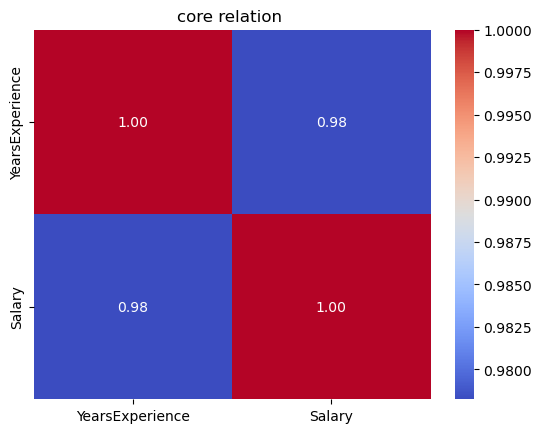

In [12]:
core=data.corr()
sns.heatmap(core,annot=True,cmap='coolwarm',fmt=".2f")
plt.title("core relation ")
plt.show()

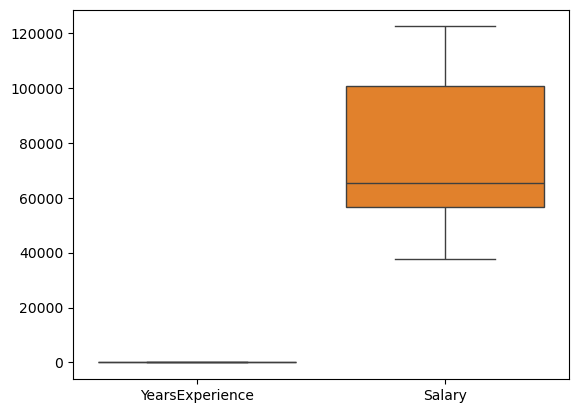

In [13]:
#data visualisation

sns.boxplot(data=data)
plt.show()

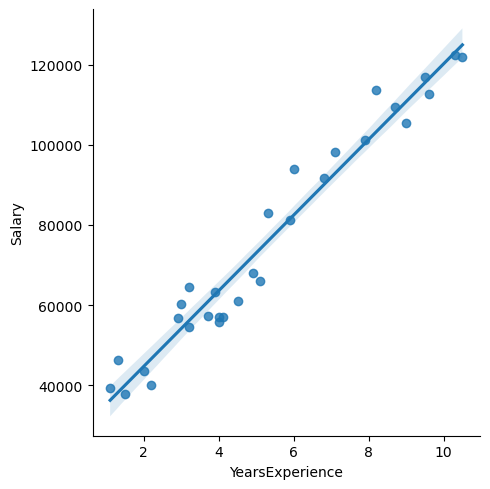

In [14]:
sns.lmplot(x="YearsExperience",y='Salary',data=data)

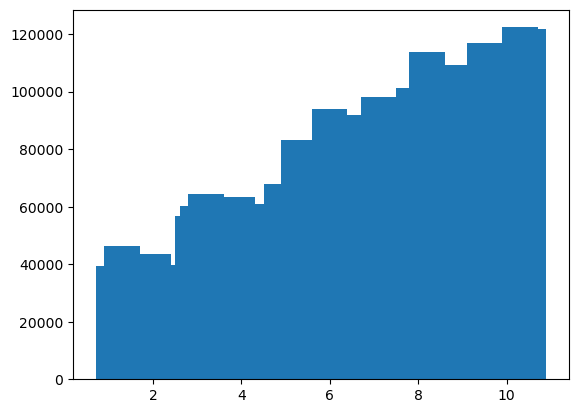

In [15]:
plt.bar(data['YearsExperience'],data['Salary'])
plt.show()

spliting data into input x and target y

In [17]:
x=data['YearsExperience']  #extract first column 'years experience'

In [18]:
x

0      1.1
1      1.3
2      1.5
3      2.0
4      2.2
5      2.9
6      3.0
7      3.2
8      3.2
9      3.7
10     3.9
11     4.0
12     4.0
13     4.1
14     4.5
15     4.9
16     5.1
17     5.3
18     5.9
19     6.0
20     6.8
21     7.1
22     7.9
23     8.2
24     8.7
25     9.0
26     9.5
27     9.6
28    10.3
29    10.5
Name: YearsExperience, dtype: float64

In [19]:
y=data['Salary']  #extract 2nd column 'salary'

In [20]:
x=x.values.reshape(-1,1)

In [21]:
x

array([[ 1.1],
       [ 1.3],
       [ 1.5],
       [ 2. ],
       [ 2.2],
       [ 2.9],
       [ 3. ],
       [ 3.2],
       [ 3.2],
       [ 3.7],
       [ 3.9],
       [ 4. ],
       [ 4. ],
       [ 4.1],
       [ 4.5],
       [ 4.9],
       [ 5.1],
       [ 5.3],
       [ 5.9],
       [ 6. ],
       [ 6.8],
       [ 7.1],
       [ 7.9],
       [ 8.2],
       [ 8.7],
       [ 9. ],
       [ 9.5],
       [ 9.6],
       [10.3],
       [10.5]])

splitting data into test data and train data

In [23]:
from sklearn.model_selection import train_test_split

In [145]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.25)


In [148]:
from sklearn.linear_model import LinearRegression

In [150]:
reg=LinearRegression()

In [152]:
reg.fit(x_train,y_train)   #trining the data using train data

LinearRegression()

In [154]:
reg.coef_

array([9400.35142652])

In [155]:
reg.intercept_

26798.68608879987

In [156]:
y_pred=reg.predict(x_test)

In [157]:
y_pred

array([ 82260.75950524,  56879.81065365,  74740.47836403, 101061.46235827,
        54059.70522569,  61579.98636691, 123622.30578191,  64400.09179486])

[]

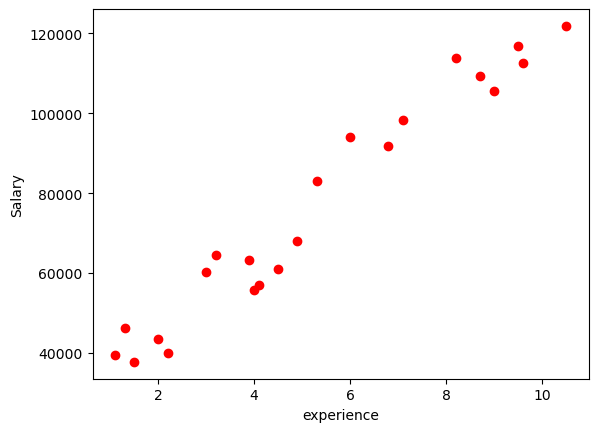

In [161]:
plt.scatter(x_train,y_train,color='red')
plt.xlabel("experience")
plt.ylabel("Salary")
plt.plot()

In [163]:
from sklearn.metrics import mean_squared_error,mean_absolute_error

In [166]:
print(mean_absolute_error(y_test,y_pred))

3491.533110328868


In [168]:
print(mean_squared_error(y_test,y_pred))

20693340.707934827


In [171]:
result=pd.DataFrame(columns=['ID','Actual','Predicted'])
result['Actual']=y_test
result['Predicted']=y_pred
result['Age']=x_test

result=result.reset_index()
result['ID']=result.index
result.head()

,index,ID,Actual,Predicted,Age
0,18,0,81363.0,82260.759505,5.9
1,7,1,54445.0,56879.810654,3.2
2,16,2,66029.0,74740.478364,5.1
3,22,3,101302.0,101061.462358,7.9
4,5,4,56642.0,54059.705226,2.9


In [176]:
from sklearn.metrics import r2_score
r2=r2_score(y_test,y_pred)  #if r2=1 its a good model
r2

0.9628759053956867